# 06 · The proposed recommender, and the full comparison (E1)

**Experiment E1 of the project plan**, with the parts it needs (steps 4, 5 and 8 of the plan's list of algorithms):

- a **hybrid** that mixes four scores: "also joined", similar descriptions, the hidden tastes of notebook 05, and a new one, **friends**;
- a **fair re-ranking** that keeps at least one slot in five for new or small groups (rule R4), no more than 2 groups of one topic per list (R5),
  and no group with more than 10% of all slots (R4);
- an **honest reason** for every suggestion (R6);
- the list members see **with personalisation off**, the default (R1): no profile, only recent activity and newness.

Then every method is scored on the test, the comparison table and chart for the report (E1).
All of it sits behind one function, `br.recommend(user_ids, data, config)`, which the experiments E2 to E6 call with other settings.

Run notebooks 01, 02 and 05 first. The code shared by all notebooks is in `boingrec.py`, in this folder.

## 0 · Settings and data

`br.Config()` holds every setting of the proposed design. Its defaults are the choices made on the practice quiz in this notebook and in notebook 05;
the checks at the end make sure they match.

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import itertools
import json
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import boingrec as br

SEED, K = br.SEED, br.K          # 0 and 5, the same in every notebook
br.use_style()
cfg = br.Config()                # the proposed design

vis = br.load_visible()          # what a recommender may read: no test file, no hidden column
ans = br.load_answers()          # the answer key: only the scoring code reads it
tested = sorted(ans.test.user_id.unique())
gids = br.group_ids(vis)
name = vis.groups.set_index('group_id').name
print(f'{len(vis.train)} visible memberships, {len(ans.test)} hidden ones, {len(tested)} users to test')
pd.Series(asdict(cfg), dtype=object).to_frame('setting').T

6428 visible memberships, 1531 hidden ones, 1406 users to test


,alpha,beta,gamma,delta,k,topic_weight,personal,off_new_w,q,c,...,burst_w,young_days,eps,m,size_share,noise_seed,seed,small_from,r9_scope,act_eps
setting,0.4,0.1,0.3,0.2,10,0.0,True,0.5,0.2,0.1,...,1.0,30,None,None,0.25,None,0,counted,joins,None


## 1 · The practice quiz

The same practice quiz as notebooks 04 and 05: 20% of the training groups of users with 3 or more are hidden. Every setting below is chosen on it.

In [3]:
fit, val = br.val_split(vis)
val_users = sorted(val.user_id.unique())
stats_fit = br.stats_for(fit, cfg)        # the statistics about other members, from the practice training data
print(f'Practice quiz: {len(val)} memberships hidden for {len(val_users)} users; {len(fit.train)} left to learn from')

Practice quiz: 1093 memberships hidden for 1090 users; 5335 left to learn from


## 2 · Statistics about other members, in one place

Everything the recommender knows about *other* members comes from one function, `br.group_stats()`: the group sizes, how many members each pair of
groups shares (X<sup>T</sup>X, used by "also joined" **and** by the AI model), and each group's recent activity. The rules about whose data counts act there,
so they reach every part at once:

- **R8:** suspended accounts never count;
- **R9:** only accounts at level *L* or more count (here *L* = 1, everyone; experiment E4 raises it and down-weights bursts of joins);
- **R10:** each member's contribution can be capped and the counts get noise (off here; experiment E3 turns it on).

With the suspended accounts left out, the "also joined" and AI-model scores are exactly those of notebooks 04 and 05.

In [4]:
stats = br.stats_for(vis, cfg)            # from all the training data, for the test
suspended = vis.users.user_id[vis.users.suspended == 1]
print(f'{len(stats.counted)} of {len(vis.users)} accounts count: the {len(suspended)} suspended ones never do '
      f'(they hold {vis.train.user_id.isin(suspended).sum()} of the {len(vis.train)} memberships).')
print(f'{len(stats.newcomers)} of the {len(gids)} groups are new (created in the last {br.NEW_DAYS} days) or small (fewer than '
      f'{br.SMALL} members); {len(stats.newcomers & set(br.discover_groups(vis.groups)))} of them are on Discover.')

no_suspended = replace(vis, train=vis.train[~vis.train.user_id.isin(suspended)])
raw = br.raw_parts(vis, tested, cfg, stats)
diff_cf = np.abs(raw['cf'] - br.also_joined_scores(no_suspended, tested)).to_numpy().max()
diff_mf = np.abs(raw['mf'] - br.hidden_tastes_scores(no_suspended, tested, k=cfg.k)).to_numpy().max()
print(f'Largest difference from "also joined" (notebook 04): {diff_cf:.1e}; from the AI model (notebook 05): {diff_mf:.1e}')

1983 of 2000 accounts count: the 17 suspended ones never do (they hold 61 of the 6428 memberships).
68 of the 150 groups are new (created in the last 30 days) or small (fewer than 10 members); 53 of them are on Discover.


Largest difference from "also joined" (notebook 04): 0.0e+00; from the AI model (notebook 05): 0.0e+00


## 3 · A fourth score: friends

A user's **friends** score for a group = how many of the user's friends are members. Only friends who may be counted and named (R6, R8):

- the friend's profile is **public** (a private profile is never counted, not even as a number);
- the friend's account counts (not suspended; level *L* or more);
- neither of the two has **blocked** the other.

In [5]:
f = vis.friendships
links = pd.concat([pd.DataFrame({'user_id': f.user_a, 'friend_id': f.user_b}),
                   pd.DataFrame({'user_id': f.user_b, 'friend_id': f.user_a})])
user = vis.users.set_index('user_id')
blocked = set(zip(vis.blocks.user_id, vis.blocks.blocked_id)) | set(zip(vis.blocks.blocked_id, vis.blocks.user_id))
ok = br.public_friends(vis, user.index, stats.counted)
print(f'{len(f)} friendships, so {len(links)} links "my friend": {len(ok)} may count.')
print(f'Left out: {(user.privacy[links.friend_id].to_numpy() == "private").sum()} links to a private profile, '
      f'{(user.suspended[links.friend_id].to_numpy() == 1).sum()} to a suspended account, '
      f'{sum((u, v) in blocked for u, v in zip(links.user_id, links.friend_id))} between people who blocked each other.')

social = br.social_scores(vis, [1], stats.counted).iloc[0]
mine = links.friend_id[links.user_id == 1]
print(f'\nUser 1 has {len(mine)} friends; {len(ok[ok.user_id == 1])} have a public profile and count. Their groups:')
social[social > 0].sort_values(ascending=False, kind='stable').rename(index=name).astype(int).to_frame('public friends in it').head(8)

5374 friendships, so 10748 links "my friend": 8390 may count.
Left out: 2279 links to a private profile, 125 to a suspended account, 0 between people who blocked each other.

User 1 has 5 friends; 4 have a public profile and count. Their groups:


,public friends in it
group_id,
Beat the IELTS,2
Finals countdown,1
Guitar club,1
Journaling streak,1
Weightlifting for beginners,1
30 days of Reading,1
Drums practice room,1
Midterms countdown,1


## 4 · The hybrid: mixing the four scores

The four scores have different scales (a sum of overlaps, an average similarity, a count of friends, a projection), so each is first **rescaled per user**
to 0-1 over the user's candidates (the best candidate gets 1, the worst 0). Then

  *s* = α · "also joined" + β · similar descriptions + γ · friends + δ · AI model.

Only the proportions matter, so the weights add up to 1. We try **every split in steps of 0.1** (286 mixes) on the practice quiz and keep the best NDCG@5.
The table shows the 10 best mixes, then each score alone.

In [6]:
parts = br.hybrid_parts(fit, val_users, cfg, stats_fit)     # the four scores, rescaled to 0-1 per user
WEIGHTS = ['alpha', 'beta', 'gamma', 'delta']
STEP = 10
grid = [tuple(w / STEP for w in ws) for ws in itertools.product(range(STEP + 1), repeat=4) if sum(ws) == STEP]
grid_rows = []
for w in grid:
    r = br.evaluate(br.top_k(br.hybrid_scores(parts, weights=w), fit), val, fit, ans.group_topic)
    grid_rows.append({**dict(zip(WEIGHTS, w)), **r.drop('users').to_dict()})
hybrid_grid = pd.DataFrame(grid_rows).astype({'coverage': int}).sort_values('ndcg@5', ascending=False, kind='stable')
hybrid_grid.index = pd.RangeIndex(1, len(hybrid_grid) + 1, name='rank')
br.save_table(hybrid_grid, 'hybrid_validation.csv', decimals=4)

best = tuple(hybrid_grid.iloc[0][WEIGHTS])
alone = hybrid_grid[(hybrid_grid[WEIGHTS] == 1).any(axis=1)]
best_lists = br.top_k(br.hybrid_scores(parts, weights=best), fit)
low, high = br.bootstrap_ci(br.relevance_per_user(best_lists, val)['ndcg@5'])
print(f'Best mix: alpha = {best[0]}, beta = {best[1]}, gamma = {best[2]}, delta = {best[3]} '
      f'(boingrec.Config: {cfg.alpha}, {cfg.beta}, {cfg.gamma}, {cfg.delta}); its 95% range: {low:.3f} to {high:.3f}')
pd.concat([hybrid_grid.head(10), alone])[WEIGHTS + ['hit_rate', 'ndcg@5', 'newcomer_share', 'gini', 'coverage']].round(3)

Best mix: alpha = 0.4, beta = 0.1, gamma = 0.3, delta = 0.2 (boingrec.Config: 0.4, 0.1, 0.3, 0.2); its 95% range: 0.453 to 0.500


,alpha,beta,gamma,delta,hit_rate,ndcg@5,newcomer_share,gini,coverage
rank,,,,,,,,,
1,0.4,0.1,0.3,0.2,0.643,0.478,0.025,0.647,103
2,0.5,0.1,0.3,0.1,0.647,0.476,0.025,0.644,101
3,0.3,0.2,0.3,0.2,0.639,0.476,0.045,0.622,114
4,0.3,0.1,0.3,0.3,0.640,0.475,0.023,0.653,103
5,0.4,0.1,0.4,0.1,0.643,0.475,0.027,0.652,108
6,0.5,0.1,0.4,0.0,0.648,0.475,0.027,0.651,105
7,0.6,0.1,0.3,0.0,0.651,0.473,0.028,0.640,101
8,0.4,0.2,0.3,0.1,0.638,0.473,0.045,0.619,113
9,0.3,0.1,0.4,0.2,0.636,0.473,0.024,0.657,107


The best mix leans on **"also joined" and friends**, with a little of the AI model and of similar descriptions. It beats each score alone on the practice
quiz. The top 10 mixes are within a few thousandths of each other, less than the uncertainty of the quiz itself, so the exact weights matter little;
what matters is that mixing helps. The hybrid still shows newcomers almost nothing (about 2% of slots): that is the re-ranker's job.

## 5 · Public topics, for rule R5

Rule R5 limits how many groups of one topic a list may hold. The recommender may not read the hidden topics, so it makes its own **public topics**:
it sorts the groups into 10 clusters by the words of their names and descriptions (KMeans on the TF-IDF vectors of notebook 04, seed 0).
The scoring code then checks how well these clusters match the hidden topics: *purity* is the share of groups that belong to their cluster's main topic.

In [7]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

clusters = br.topic_clusters(vis, cfg.clusters)       # public: from names and descriptions only
topic = ans.group_topic.reindex(clusters.index)       # scoring code only
cross = pd.crosstab(clusters, topic)
match = {'clusters': int(cfg.clusters), 'seed': SEED,
         'purity': round(float(cross.max(axis=1).sum() / len(clusters)), 4),
         'normalized_mutual_info': round(float(normalized_mutual_info_score(topic, clusters)), 4),
         'adjusted_rand_index': round(float(adjusted_rand_score(topic, clusters)), 4)}
(br.RESULTS / 'topic_clusters_match.json').write_text(json.dumps(match, indent=2))
clusters.to_frame().assign(name=name).to_csv(br.RESULTS / 'topic_clusters.csv')
print(f'Purity {match["purity"]:.2f} (1 = each cluster is one topic), normalised mutual information {match["normalized_mutual_info"]:.2f}')
pd.DataFrame({'groups': cross.sum(axis=1), 'main hidden topic': cross.idxmax(axis=1),
              'its share': (cross.max(axis=1) / cross.sum(axis=1)).round(2),
              'examples': clusters.groupby(clusters).apply(lambda s: ', '.join(name[s.index[:3]]))})

Purity 0.49 (1 = each cluster is one topic), normalised mutual information 0.43


,groups,main hidden topic,its share,examples
cluster,,,,
0,9,coding,0.67,"Relativity study group, Entrance exams account..."
1,20,coding,0.50,"Finals countdown, Journaling streak, Algorithm..."
2,12,careers,0.50,"Networking club, Networking 101, Freelancing club"
3,24,coding,0.29,"Mastering Probability, Geometry without tears,..."
4,7,languages,0.57,"Daily Rust, Rust project club, Arabic conversa..."
5,13,music,0.69,"Guitar club, Curious about Thermodynamics, Lea..."
6,14,fitness,0.36,"Korean conversation club, Spanish for beginner..."
7,16,maths,0.69,"3D modelling club, Astronomy club, Calculus he..."
8,22,fitness,0.23,"Weightlifting for beginners, 30 days of Readin..."


The public topics are only half right (purity about 0.5). Group descriptions in this community reuse the same phrases across topics
("Practice sessions and honest feedback", "Getting ready for a trip or an exam in ..."), so some clusters group by wording rather than subject.
R5 is therefore a looser diversity rule than "at most 2 per real topic"; better public topics (members choosing a group's topic when they create it)
would make it sharper.

## 6 · Fair re-ranking (R4, R5)

The re-ranker builds each list **one slot at a time**. For the next slot it takes the candidate with the best

  λ · relevance − (1 − λ) · (its highest similarity to the groups already picked)

(this is *MMR*: with λ = 1 only relevance counts; lower λ favours groups unlike those already in the list). Among the candidates, it keeps three rules:

- **quota q = 20%** (R4): at least 1 slot in 5 goes to a new or small group, the most relevant one, if no newcomer made the list on its own;
- **topic cap n = 2** (R5): at most 2 groups of one public topic per list;
- **global cap c = 10%** (R4): no group gets more than 10% of all slots. Users are served in a fixed shuffled order (seed 0); once a group reaches its cap it is skipped.

If no candidate could keep every rule, the rules would be relaxed in that order (the counts are printed below: they stay at 0).
λ is chosen on the practice quiz from 1, 0.9, 0.8, 0.7 and 0.5. Besides the usual columns: *diversity* = 1 − the average description similarity of
the pairs in a list; *clusters_per_list* = public topics per list; *quota_slots* = share of slots the quota changed.

In [8]:
sim = br.description_similarity(vis)
created = vis.groups.set_index('group_id').created_day
new_ids = set(created.index[created > br.TODAY - br.NEW_DAYS])

def score_lists(recs, truth, v):
    # evaluate() plus the diversity measures and what the re-ranker did
    lists = br.lists_from(recs)
    row = br.evaluate(lists, truth, v, ans.group_topic)
    row['diversity'] = br.list_diversity(lists, sim)
    row['clusters_per_list'] = float(np.mean([clusters[l].nunique() for l in lists.values()]))
    row['quota_slots'] = recs.forced.mean()
    row['new_groups_shown'] = len({g for l in lists.values() for g in l} & new_ids)
    row['times_relaxed'] = sum(recs.attrs['relaxed'].values())
    return row

NO_RERANK = dict(q=0, c=None, n=None, lam=1.0)
LAMBDAS = [1.0, 0.9, 0.8, 0.7, 0.5]
rerank_rows = {'Hybrid, no re-ranking': score_lists(br.recommend(val_users, fit, replace(cfg, **NO_RERANK), stats_fit), val, fit)}
for lam in LAMBDAS:
    rerank_rows[f'lambda = {lam}'] = score_lists(br.recommend(val_users, fit, replace(cfg, lam=lam), stats_fit), val, fit)
rerank_table = pd.DataFrame(rerank_rows).T
br.save_table(rerank_table, 'rerank_validation.csv', decimals=4)

LAM = LAMBDAS[int(np.argmax(rerank_table.loc[[f'lambda = {lam}' for lam in LAMBDAS], 'ndcg@5'].to_numpy()))]   # ties: the larger
print(f'Chosen: lambda = {LAM} (boingrec.Config: {cfg.lam})')
rerank_table[['ndcg@5', 'newcomer_share', 'gini', 'coverage', 'largest_share', 'topics_per_list', 'clusters_per_list',
              'diversity', 'quota_slots', 'times_relaxed']].round(3)

Chosen: lambda = 1.0 (boingrec.Config: 1.0)


,ndcg@5,newcomer_share,gini,coverage,largest_share,topics_per_list,clusters_per_list,diversity,quota_slots,times_relaxed
"Hybrid, no re-ranking",0.478,0.025,0.647,103.0,0.039,2.501,3.456,0.899,0.000,0.0
lambda = 1.0,0.465,0.202,0.530,122.0,0.036,2.396,3.700,0.920,0.179,0.0
lambda = 0.9,0.464,0.201,0.531,124.0,0.036,2.478,3.811,0.932,0.181,0.0
lambda = 0.8,0.464,0.201,0.535,125.0,0.034,2.561,3.926,0.944,0.182,0.0
lambda = 0.7,0.458,0.201,0.539,125.0,0.035,2.688,4.029,0.956,0.182,0.0
lambda = 0.5,0.436,0.201,0.535,128.0,0.036,2.983,4.222,0.977,0.181,0.0


The re-ranking lifts the newcomer share from about 2% to **20%** for a small loss of accuracy, and spreads the slots over more groups
(lower Gini, higher coverage). λ = 1 is the most accurate: the topic cap (n = 2) already keeps lists varied, and pushing for more variety (lower λ)
costs accuracy on this quiz. MMR stays in the design as a dial; experiment E2 sweeps λ and q together.

## 7 · Personalisation off (R1): what every member sees by default

With personalisation off, nothing about the member is used except which groups they already joined and marked "not interested" (they are never suggested).
Every member gets the same scores:

- **recent activity**: posts and likes on posts of the last 30 days (log scale; the most active group gets 1);
- **newness**: 1 for a group created today, falling to 0 at 30 days old;

  score = (1 − *w*) · activity + *w* · newness,

then the same filters and re-ranking. Accuracy alone would always pick *w* = 0 (active groups are big groups): that is the popularity trap.
So the rule is: pick the *w* whose share of slots for new or small groups is closest to what a fair lottery (random suggestions) gives them on the
practice quiz, so that newcomers get a real chance without the list becoming only empty new groups.

In [9]:
OFF_WEIGHTS = [0, 0.25, 0.5, 0.75, 1]
off_rows = {f'newness weight {w}': score_lists(br.recommend(val_users, fit, replace(cfg, personal=False, off_new_w=w), stats_fit), val, fit)
            for w in OFF_WEIGHTS}
off_table = pd.DataFrame(off_rows).T
br.save_table(off_table, 'off_validation.csv', decimals=4)

lottery = pd.read_csv(br.RESULTS / 't6_validation.csv', index_col=0).loc[br.label('random'), 'newcomer_share']
OFF_W = OFF_WEIGHTS[int(np.argmin(np.abs(off_table['newcomer_share'].to_numpy() - lottery)))]
print(f'Random suggestions give new or small groups {lottery:.0%} of the slots on the practice quiz. '
      f'Chosen: newness weight {OFF_W} (boingrec.Config: {cfg.off_new_w})')
off_table[['hit_rate', 'ndcg@5', 'newcomer_share', 'new_groups_shown', 'gini', 'coverage', 'largest_share', 'topics_per_list']].round(3)

Random suggestions give new or small groups 44% of the slots on the practice quiz. Chosen: newness weight 0.5 (boingrec.Config: 0.5)


,hit_rate,ndcg@5,newcomer_share,new_groups_shown,gini,coverage,largest_share,topics_per_list
newness weight 0,0.172,0.108,0.200,1.0,0.921,15.0,0.1,3.363
newness weight 0.25,0.172,0.108,0.200,3.0,0.921,14.0,0.1,3.745
newness weight 0.5,0.121,0.065,0.411,6.0,0.921,13.0,0.1,3.988
newness weight 0.75,0.002,0.001,1.000,11.0,0.922,11.0,0.1,4.000
newness weight 1,0.002,0.001,1.000,11.0,0.922,11.0,0.1,4.000


With *w* = 0.5, about 40% of the slots go to new or small groups, as with a lottery, and the rest to the most active groups.
Because every member sees the same list, it is unequal (high Gini): the global cap (no group above 10% of all slots) is what spreads it over more than
10 groups. It is much less accurate than the personal methods, which is the honest price of not profiling anyone.

## 8 · Reasons (R6)

Each suggestion shows one reason, from a fixed template, never generated text. The reason is the part that adds the most to the score
(each part's contribution is returned by `recommend()`, so experiment E6 can check this); a slot that came from the quota says so.

| reason_code | Example | When |
|---|---|---|
| shared_members | "85 members of Finals countdown are in it" | "also joined" adds the most |
| similar_group | "Similar to Journaling streak, which you joined" or "Because you're in Finals countdown" | similar descriptions, or the AI model, adds the most |
| friend | "Your friend user 68 is a member" | friends add the most (public profiles only) |
| topic | "Matches a topic you picked: languages" | the member's chosen topics add the most (off here: topic weight 0, notebook 04) |
| new_group | "A new group: we show new groups so they get a fair chance" ("A small group: ...") | the slot came from the quota, or newness adds the most |
| active | "Active this week" ("Active this month") | personalisation off, activity adds the most |

User 1 again: the proposed design, then the default list with personalisation off.

In [10]:
show = ['rank', 'group_id', 'score', 'reason_code', 'reason_text', 'forced'] + [f'part_{p}' for p in br.PARTS]
one = br.recommend([1], vis, cfg, stats)          # alone, so the global cap does not apply
print('User 1 is in:', ', '.join(name[sorted(vis.train.group_id[vis.train.user_id == 1])]))
print('Hidden (the answer):', ', '.join(name[sorted(ans.test.group_id[ans.test.user_id == 1])]))
one.assign(group=one.group_id.map(name))[['rank', 'group'] + show[2:]].round(3)

User 1 is in: Finals countdown, Journaling streak, Korean conversation club, Midterms countdown
Hidden (the answer): Entrance exams accountability group


,rank,group,score,reason_code,reason_text,forced,part_cf,part_content,part_social,part_mf
0,1,SAT prep squad,0.767,shared_members,85 members of Finals countdown are in it,False,0.400,0.017,0.15,0.200
1,2,30 days of Reading,0.572,shared_members,46 members of Journaling streak are in it,False,0.243,0.000,0.15,0.179
2,3,MCAT countdown,0.556,shared_members,49 members of Finals countdown are in it,False,0.248,0.034,0.15,0.124
3,4,Beat the IELTS,0.512,friend,Your friend user 68 and 1 other friend are mem...,False,0.118,0.013,0.30,0.082
4,5,GRE study hall,0.144,new_group,A small group: we show small groups so they ge...,True,0.028,0.058,0.00,0.058


In [11]:
off_one = br.recommend([1], vis, replace(cfg, personal=False), stats)
off_one.assign(group=off_one.group_id.map(name))[['rank', 'group', 'score', 'reason_code', 'reason_text', 'part_active', 'part_new']].round(3)

,rank,group,score,reason_code,reason_text,part_active,part_new
0,1,Mandarin conversation club,0.569,new_group,A new group: we show new groups so they get a ...,0.069,0.500
1,2,Calculus problem of the day,0.502,new_group,A new group: we show new groups so they get a ...,0.069,0.433
2,3,Digital painting club,0.485,new_group,A new group: we show new groups so they get a ...,0.069,0.417
3,4,Guitar for beginners,0.476,new_group,A new group: we show new groups so they get a ...,0.109,0.367
4,5,Algorithms study group,0.468,active,Active this week,0.468,0.000


## 9 · Experiment E1: the full comparison on the test set

Every method suggests 5 groups to each of the 1,406 tested users, learning only from the training data, with the settings chosen on the practice quiz.
The first four rows are notebook 04's table (unchanged), the fifth is notebook 05's AI model. The last three come from `recommend()`:
the hybrid without re-ranking, **the proposed design** (hybrid + fair re-ranking), and personalisation off (served together, so the 10% cap is shared
by all 1,406 users).

In [12]:
ORDER = ['random', 'popularity', 'also_joined', 'descriptions', 'hidden_tastes', 'hybrid', 'reranked', 'off']
recs = {'hybrid': br.recommend(tested, vis, replace(cfg, **NO_RERANK), stats),
        'reranked': br.recommend(tested, vis, cfg, stats),
        'off': br.recommend(tested, vis, replace(cfg, personal=False), stats)}
test_lists = {
    'random': br.random_lists(vis, tested),
    'popularity': br.top_k(br.popularity_scores(vis, tested), vis),
    'also_joined': br.top_k(br.also_joined_scores(vis, tested), vis),
    'descriptions': br.top_k(br.similar_descriptions_scores(vis, tested, topic_weight=cfg.topic_weight), vis),
    'hidden_tastes': br.top_k(br.hidden_tastes_scores(vis, tested, k=cfg.k), vis),
    **{m: br.lists_from(r) for m, r in recs.items()}}
e1 = pd.DataFrame({br.label(m): br.evaluate(test_lists[m], ans.test, vis, ans.group_topic) for m in ORDER}).T
e1[['users', 'coverage']] = e1[['users', 'coverage']].astype(int)
br.save_table(e1, 'e1_methods.csv')
e1.round(3)

,users,hit_rate,precision@5,recall@5,ndcg@5,newcomer_share,gini,coverage,largest_share,topics_per_list
Random (floor),1406,0.048,0.010,0.043,0.025,0.417,0.079,129,0.010,4.063
Popularity (today),1406,0.220,0.044,0.207,0.131,0.000,0.953,10,0.174,3.228
"""Also joined""",1406,0.640,0.136,0.621,0.499,0.027,0.599,94,0.031,2.037
Similar descriptions,1406,0.263,0.054,0.247,0.159,0.416,0.502,125,0.038,1.976
Hidden tastes (AI model),1406,0.610,0.129,0.591,0.475,0.005,0.645,76,0.037,2.251
Hybrid,1406,0.687,0.146,0.668,0.541,0.020,0.640,106,0.038,2.555
Hybrid + fair re-ranking,1406,0.656,0.139,0.636,0.528,0.203,0.511,125,0.033,2.402
Personalisation off,1406,0.098,0.020,0.091,0.058,0.547,0.921,14,0.100,4.374


**How sure are we?** 95% ranges from resampling the users (as in notebook 04), and the **price of fairness**: how much NDCG@5 the re-ranking costs
each user, compared with the hybrid alone (a paired range: the same resampled users for both).

In [13]:
per_user = {m: br.relevance_per_user(test_lists[m], ans.test) for m in ORDER}
ci_rows = {}
for m in ORDER:
    row = {}
    for metric in ['hit_rate', 'ndcg@5']:
        low, high = br.bootstrap_ci(per_user[m][metric])
        row.update({metric: per_user[m][metric].mean(), f'{metric} low': low, f'{metric} high': high})
    ci_rows[br.label(m)] = row
ci = pd.DataFrame(ci_rows).T
br.save_table(ci, 'e1_methods_ci.csv')

cost = per_user['hybrid']['ndcg@5'] - per_user['reranked']['ndcg@5']
low, high = br.bootstrap_ci(cost)
fairness = {'ndcg@5 hybrid': e1.loc[br.label('hybrid'), 'ndcg@5'], 'ndcg@5 proposed': e1.loc[br.label('reranked'), 'ndcg@5'],
            'cost': float(cost.mean()), 'cost low': low, 'cost high': high,
            'relative cost': float(cost.mean() / e1.loc[br.label('hybrid'), 'ndcg@5']),
            'newcomer share hybrid': e1.loc[br.label('hybrid'), 'newcomer_share'],
            'newcomer share proposed': e1.loc[br.label('reranked'), 'newcomer_share']}
fairness = {k: round(float(v), 4) for k, v in fairness.items()}
(br.RESULTS / 'e1_price_of_fairness.json').write_text(json.dumps(fairness, indent=2))
print(f'The re-ranking costs {fairness["cost"]:.3f} NDCG@5 ({fairness["relative cost"]:.1%} of the hybrid\'s; 95% range '
      f'{low:.3f} to {high:.3f}) and lifts the newcomer share from {fairness["newcomer share hybrid"]:.1%} to {fairness["newcomer share proposed"]:.1%}.')
ci.round(3)

The re-ranking costs 0.013 NDCG@5 (2.3% of the hybrid's; 95% range 0.008 to 0.017) and lifts the newcomer share from 2.0% to 20.3%.


,hit_rate,hit_rate low,hit_rate high,ndcg@5,ndcg@5 low,ndcg@5 high
Random (floor),0.048,0.038,0.060,0.025,0.019,0.033
Popularity (today),0.220,0.198,0.243,0.131,0.117,0.146
"""Also joined""",0.640,0.616,0.666,0.499,0.476,0.522
Similar descriptions,0.263,0.240,0.287,0.159,0.144,0.176
Hidden tastes (AI model),0.610,0.585,0.634,0.475,0.452,0.496
Hybrid,0.687,0.661,0.711,0.541,0.517,0.563
Hybrid + fair re-ranking,0.656,0.632,0.680,0.528,0.504,0.551
Personalisation off,0.098,0.083,0.115,0.058,0.048,0.068


## 10 · The chart

Relevance (NDCG@5) and the share of slots for new or small groups, with the same colour for each method as in every other figure.
The dashed line is the quota (q = 20%).

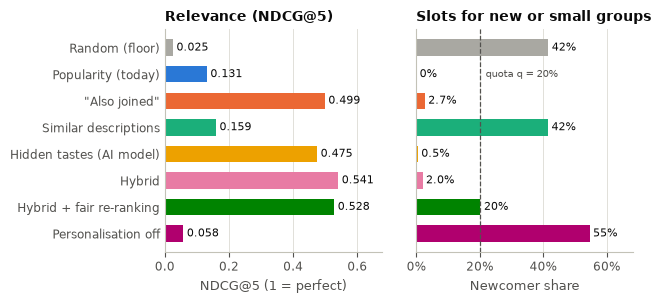

In [14]:
labels = [br.label(m) for m in ORDER]
y = np.arange(len(ORDER))[::-1]                       # first method at the top
percent = lambda v: '0%' if v == 0 else f'{v:.1%}' if v < 0.1 else f'{v:.0%}'   # one decimal below 10%
panels = [('ndcg@5', 'Relevance (NDCG@5)', 'NDCG@5 (1 = perfect)', '{:.3f}'.format),
          ('newcomer_share', 'Slots for new or small groups', 'Newcomer share', percent)]
fig, axes = plt.subplots(1, 2, figsize=(br.WIDTH, 3.1), sharey=True)
for ax, (col, title, xlabel, fmt) in zip(axes, panels):
    values = e1.loc[labels, col].to_numpy()
    ax.barh(y, values, height=0.62, color=[br.colour(m) for m in ORDER])
    for yi, v in zip(y, values):
        ax.text(v + values.max() * 0.02, yi, fmt(v), va='center', fontsize=8, color=br.INK)
    ax.set_xlim(0, values.max() * 1.25)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True)
    ax.tick_params(axis='y', length=0)
axes[0].set_yticks(y, labels)
axes[1].axvline(cfg.q, color=br.MUTED, linestyle='--', linewidth=0.9)
axes[1].text(cfg.q, y[ORDER.index('popularity')], f'  quota q = {cfg.q:.0%}', color=br.MUTED, fontsize=7.5, va='center')
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.tight_layout(w_pad=2)
br.save_fig(fig, 'e1_methods.png')
plt.show()

## 11 · What the reasons say, and what members see by default

How often each reason is shown on the test, for the proposed design and for personalisation off; then the groups the default list shows most.

In [15]:
reasons = pd.DataFrame({br.label(m): recs[m].reason_code.value_counts() for m in ['reranked', 'off']}).reindex(br.REASON_CODES).fillna(0).astype(int)
reasons = pd.concat([reasons, (reasons / reasons.sum()).add_suffix(' (share)')], axis=1)
br.save_table(reasons, 'e1_reasons.csv')

shown = br.exposure(test_lists['off'], br.discover_groups(vis.groups))
default_list = pd.DataFrame({'group': name[shown.index], 'members': stats.sizes[shown.index].astype(int),
                             'new': created[shown.index] > br.TODAY - br.NEW_DAYS, 'slots': shown,
                             'share of slots': (shown / shown.sum()).round(3)})
display(reasons.round(3))
default_list[default_list.slots > 0].sort_values('slots', ascending=False, kind='stable')

,Hybrid + fair re-ranking,Personalisation off,Hybrid + fair re-ranking (share),Personalisation off (share)
reason_code,,,,
shared_members,3942,0,0.561,0.000
similar_group,59,0,0.008,0.000
friend,1741,0,0.248,0.000
topic,0,0,0.000,0.000
new_group,1288,3843,0.183,0.547
active,0,3187,0.000,0.453
discover,0,0,0.000,0.000


,group,members,new,slots,share of slots
group_id,,,,,
7,Korean conversation club,272,False,703,0.100
25,Algorithms study group,217,False,703,0.100
143,Guitar for beginners,1,True,703,0.100
144,Linear algebra study group,1,True,703,0.100
147,Digital painting club,2,True,703,0.100
149,Calculus problem of the day,1,True,703,0.100
150,Mandarin conversation club,1,True,703,0.100
23,Midterms countdown,220,False,614,0.087
10,Weightlifting for beginners,291,False,591,0.084


## 12 · Checks

In [16]:
from collections import Counter

allowed = br.candidate_mask(vis, tested)
proposed = recs['reranked']
newcomer = stats.newcomers
user_groups = vis.train.groupby('user_id').group_id.apply(set)
friend_pairs = set(zip(links.user_id, links.friend_id))
members = set(zip(vis.train.user_id, vis.train.group_id))
part_cols = [f'part_{p}' for p in br.PARTS + ['active', 'new']]

def reason_matches(row):
    # the reason names the part that adds the most (a quota slot says new_group)
    if row.forced:
        return row.reason_code == 'new_group'
    if not row.personal:
        top = 'active' if row.part_active >= row.part_new else 'new'
        return row.reason_code == {'active': 'active', 'new': 'new_group'}[top]
    top = max(br.PARTS, key=lambda p: row[f'part_{p}'])
    expected = {'cf': [('shared_members', '')], 'content': [('similar_group', 'Similar to'), ('topic', '')],
                'social': [('friend', '')], 'mf': [('similar_group', 'Because')]}[top]
    return any(row.reason_code == code and row.reason_text.startswith(start) for code, start in expected)

def friend_ok(row):
    v = row.reason_ref
    return (user.privacy[v] == 'public' and user.suspended[v] == 0 and (row.user_id, v) in friend_pairs
            and (row.user_id, v) not in blocked and (v, row.group_id) in members)

hooks_work = []   # E3 and E4 (notebooks 08, 09) filled the hooks: each must change the statistics, never be silently ignored
for change in [dict(eps=1.0, m=5), dict(m=5), dict(burst_w=0.5)]:
    hooks_work.append(not np.array_equal(br.stats_for(vis, replace(cfg, **change)).co.to_numpy(), stats.co.to_numpy()))
try:
    br.stats_for(vis, replace(cfg, eps=1.0))      # noise without a cap m gives no guarantee: it must stop with a clear message
    hooks_work.append(False)
except ValueError:
    hooks_work.append(True)
again = br.recommend(tested, vis, cfg, stats)
hybrid_top_k = br.top_k(br.hybrid_scores(br.hybrid_parts(vis, tested, cfg, stats), cfg), vis)

checks = {
    'every tested user gets exactly 5 different groups from every method':
        all(len(set(lists[u])) == K == len(lists[u]) for lists in test_lists.values() for u in tested),
    'every suggestion is allowed: on Discover, not joined, not marked "not interested" (R7, R8)':
        all(allowed.loc[u, g] for lists in test_lists.values() for u in tested for g in lists[u]),
    'quota (R4): every proposed list has at least ceil(q x 5) new or small groups, and the newcomer share is at least q':
        all(sum(g in newcomer for g in test_lists['reranked'][u]) >= np.ceil(cfg.q * K - 1e-9) for u in tested)
        and e1.loc[br.label('reranked'), 'newcomer_share'] >= cfg.q,
    'topic cap (R5): no proposed list has more than n groups of one public topic':
        all(max(Counter(clusters[test_lists['reranked'][u]]).values()) <= cfg.n for u in tested),
    'global cap (R4): no group gets more than c of all slots (proposed and personalisation off)':
        all(e1.loc[br.label(m), 'largest_share'] <= cfg.c + 1e-12 for m in ['reranked', 'off']),
    'no rule had to be relaxed on the test': all(sum(r.attrs['relaxed'].values()) == 0 for r in recs.values()),
    'the parts add up to the score, on every row': all(np.allclose(r[part_cols].sum(axis=1), r.score) for r in recs.values()),
    'the reason is always the part that adds the most, or the quota (R6, by construction)':
        all(r.apply(reason_matches, axis=1).all() for r in recs.values()),
    'every friend reason names a public, not suspended, not blocked friend who is in the group (R6, R8)':
        all(proposed[proposed.reason_code == 'friend'].apply(friend_ok, axis=1)),
    'every "shared members" or "similar group" reason names a group the user is in':
        all(row.reason_ref in user_groups[row.user_id]
            for row in proposed[proposed.reason_code.isin(['shared_members', 'similar_group'])].itertuples()),
    'the hybrid beats each of its four scores alone on the practice quiz':
        hybrid_grid['ndcg@5'].iloc[0] > alone['ndcg@5'].max(),
    'recommend() without re-ranking gives exactly the hybrid\'s top 5': test_lists['hybrid'] == hybrid_top_k,
    'group_stats() rebuilds "also joined" and the AI model exactly (without the suspended accounts)': diff_cf < 1e-12 and diff_mf < 1e-9,
    'the first four rows equal notebook 04\'s table (E1 version 1)':
        e1.iloc[:4].round(3).equals(pd.read_csv(br.RESULTS / 'e1_v1.csv', index_col=0).round(3).set_axis(e1.index[:4])),
    'boingrec.Config holds the choices made here and in notebook 05 (weights, lambda, newness weight, tastes)':
        best == (cfg.alpha, cfg.beta, cfg.gamma, cfg.delta) and LAM == cfg.lam and OFF_W == cfg.off_new_w and cfg.k == br.TASTES,
    'the privacy and fake-account hooks are not silently ignored: m, eps and burst_w change the statistics, eps without m stops with a clear message':
        all(hooks_work),
    'same seed, same results: recommend() run again gives the same rows': again.equals(proposed),
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not set(zip(vis.train.user_id, vis.train.group_id)) & set(zip(ans.test.user_id, ans.test.group_id)),
}
for check, ok_ in checks.items():
    print('✓' if ok_ else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ every tested user gets exactly 5 different groups from every method
✓ every suggestion is allowed: on Discover, not joined, not marked "not interested" (R7, R8)
✓ quota (R4): every proposed list has at least ceil(q x 5) new or small groups, and the newcomer share is at least q
✓ topic cap (R5): no proposed list has more than n groups of one public topic
✓ global cap (R4): no group gets more than c of all slots (proposed and personalisation off)
✓ no rule had to be relaxed on the test
✓ the parts add up to the score, on every row
✓ the reason is always the part that adds the most, or the quota (R6, by construction)
✓ every friend reason names a public, not suspended, not blocked friend who is in the group (R6, R8)
✓ every "shared members" or "similar group" reason names a group the user is in
✓ the hybrid beats each of its four scores alone on the practice quiz
✓ recommend() without re-ranking gives exactly the hybrid's top 5
✓ group_stats() rebuilds "also joined" and the AI model exa

## What we learned

- **The hybrid is the most relevant method:** on the test, NDCG@5 = **0.541** and a hit rate of **69%**, against 0.499 for "also joined" alone,
  0.475 for the AI model and 0.131 for today's BOING. The weights chosen on the practice quiz are 0.4 "also joined", 0.1 similar descriptions,
  0.3 friends, 0.2 AI model; mixing beats each score alone, but the exact weights matter little.
- **The proposed design (hybrid + fair re-ranking) gives new or small groups 20% of the slots** (the hybrid alone: 2%; today's BOING: 0%) for a cost of
  **0.013 NDCG@5** (2.3% of the hybrid's; 95% range 0.008 to 0.017), and shows 125 of the 129 Discover groups (today: 10), with a Gini of 0.511 (today: 0.953).
  No group takes more than 3.3% of the slots and no list has more than 2 groups of one public topic. λ = 1 was best: the topic cap already keeps lists varied.
- **Personalisation off** (the default, R1) uses no profile at all: NDCG@5 = 0.058, still above random (0.025), with 55% of slots for new or small groups
  but only 14 groups shown, because everyone sees nearly the same list; the 10% cap is what spreads it.
- **Every suggestion has a true reason** from a fixed template. In the proposed design most say how many members of one of your groups are in it,
  about a quarter name a public friend, and about one in five is a quota slot that says it is there to give a new or small group a fair chance.
- The public topic clusters match the hidden topics only half the time (purity about 0.5), so R5 is a loose diversity rule here.
- Files: `results/e1_methods.csv` (the table), `results/e1_methods_ci.csv` (95% ranges), `results/e1_price_of_fairness.json`, `results/e1_reasons.csv`,
  `results/hybrid_validation.csv`, `results/rerank_validation.csv`, `results/off_validation.csv`, `results/topic_clusters.csv`,
  `results/topic_clusters_match.json`, `figures/e1_methods.png`.

**For the experiments:** `br.recommend(user_ids, vis, br.Config(...))` runs the whole design with any setting. E2 sweeps `q` and `lam` (and `c`, `n`);
E3 fills in the noise and clipping hooks (`eps`, `m`) in `br.group_stats()`; E4 the fake-account hooks (`L` already works, `burst_w` is a hook);
E6 checks the reasons with the `part_*` columns.